# Lab Assignment 3 - Scientific Computing Lab

## Submitted by - Naman Jain, SC26M013

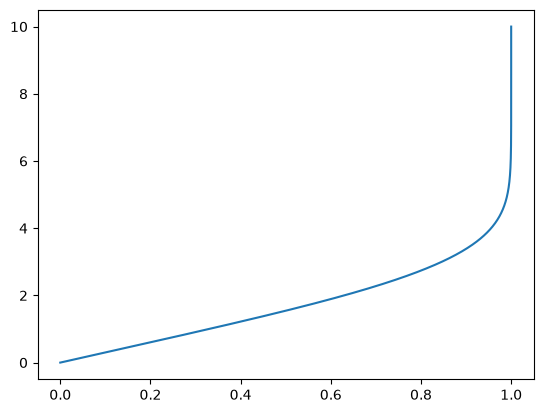

In [21]:
import numpy as np
import matplotlib.pyplot as plt

eta_inf = 10

def first_order(u1, u2, u3):
    Y = np.array([u1, u2, u3])
    G = np.array([[0, 1, 0],[0, 0, 1],[0, 0, -u1/2]])

    Y_d = G @ Y
    return Y_d

def RK3(s, eta_inf):
    h = 0.01
    N = int(eta_inf / h)
    Y = np.zeros((N + 1, 3))
    eta = np.linspace(0, eta_inf, N + 1)

    Y[0, 0] = 0
    Y[0, 1] = 0 
    Y[0, 2] = s
    
    for i in range(N):
        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])
        K2 = h * first_order(Y[i, 0] + K1[0]/2, Y[i, 1] + K1[1]/2, Y[i, 2] + K1[2]/2)
        K3 = h * first_order(Y[i, 0] - K1[0] + 2*K2[0], Y[i, 1] - K1[1] + 2*K2[1], Y[i, 2] - K1[2] + 2*K2[2])

        Y[i+1, 0] = Y[i, 0] + (K1[0] + 4*K2[0] + K3[0])/6
        Y[i+1, 1] = Y[i, 1] + (K1[1] + 4*K2[1] + K3[1])/6
        Y[i+1, 2] = Y[i, 2] + (K1[2] + 4*K2[2] + K3[2])/6

        err = Y[-1, 1] - 1

    return eta, Y, err

def error(s):
    error = RK3(s, eta_inf)[2]
    return error 

def bisection(sl, su, eps):
    while (su - sl)/2 > eps:
        s = (su + sl)/2
        if error(s) == 0:
            return s 
            
        if error(sl)*error(s) < 0:
            su = s
        else:
            sl = s
    return s 

sl = 0
su = 1
eps = 1e-10

eta, Y, err1 = RK3(bisection(sl, su, eps), eta_inf)
plt.plot(Y[:, 1], eta)
plt.show()